Analyse exploratoire (EDA) et clustering non supervisé

In [8]:
import pandas as pd
import numpy as np
#DataCoSupplyChain.zip = pd.read_csv("./DataCoSupplyChain.zip")
chemin_zip = "data/raw/DataCoSupplyChainDataset.zip" # le fichier zip est dans le fichier du notebook
df = pd.read_csv(chemin_zip, encoding="latin1") #lecture du fichier csv dans le zip
df.head(10)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class
5,TRANSFER,6,4,18.580000,294.980011,Shipping canceled,0,73,Sporting Goods,Tonawanda,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/19/2018 11:03,Standard Class
6,DEBIT,2,1,95.180000,288.420013,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 10:42,First Class
7,TRANSFER,2,1,68.430000,285.140015,Late delivery,1,73,Sporting Goods,Miami,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 10:21,First Class
8,CASH,3,2,133.720001,278.589996,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 10:00,Second Class
9,CASH,2,1,132.149994,275.309998,Late delivery,1,73,Sporting Goods,San Ramon,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 9:39,First Class


In [9]:
df.shape #affiche le nombre de lignes et de colonnes du dataframe

(180519, 53)

In [12]:
df.info(max_cols=None) #informations sur le dataframe

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [13]:
manquants = df.isnull().sum() #compte le nombre de valeurs manquantes par colonne
manquants = manquants[manquants > 0].sort_values(ascending=False) #filtre les colonnes avec des valeurs manquantes
manquants #affiche le nombre de valeurs manquantes par colonne

Product Description    180519
Order Zipcode          155679
Customer Lname              8
Customer Zipcode            3
dtype: int64

Nous avons 4 colonnes avec des valeurs manquantes

In [38]:
df = df.drop(columns=["Product Description", "Order Zipcode"], errors="ignore")
df = df.dropna(subset=["Customer Lname", "Customer Zipcode"])
print(df.shape)

(180508, 51)


In [18]:
df["Late_delivery_risk"].value_counts() #compte le nombre de valeurs uniques dans la colonne "Late_delivery_risk"
df["Late_delivery_risk"].value_counts(normalize=True) #affiche le pourcentage de valeurs uniques dans la colonne "Late_delivery_risk"

Late_delivery_risk
1    0.548291
0    0.451709
Name: proportion, dtype: float64

Risk de retard de livraison en %, 54,82% de chance de retard contre 45,17%

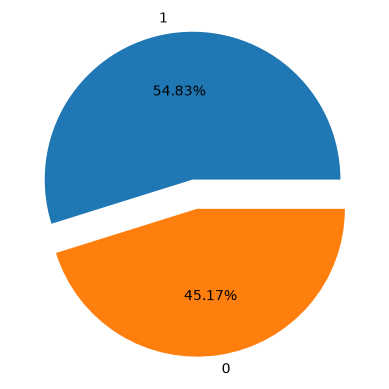

In [23]:
Late_delivery_risk = df["Late_delivery_risk"].value_counts()
Late_delivery_risk.plot.pie(
    autopct="%0.2f%%",
    explode=[0.1] * len(Late_delivery_risk),
);

In [26]:
Late_delivery_risk=df["Late_delivery_risk"].value_counts()
print(Late_delivery_risk   )

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


In [20]:
df["Shipping Mode"].value_counts() #compte le nombre de valeurs uniques dans la colonne "Shipping Mode"

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

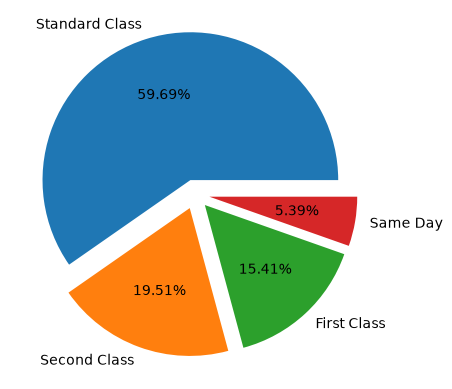

In [31]:
Shiping_Mode = df["Shipping Mode"].value_counts()
Shiping_Mode.plot.pie(
    autopct="%0.2f%%",
    explode=[0.1] * len(Shiping_Mode),
);


In [6]:
df.describe() #statistiques descriptives sur le dataframe

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


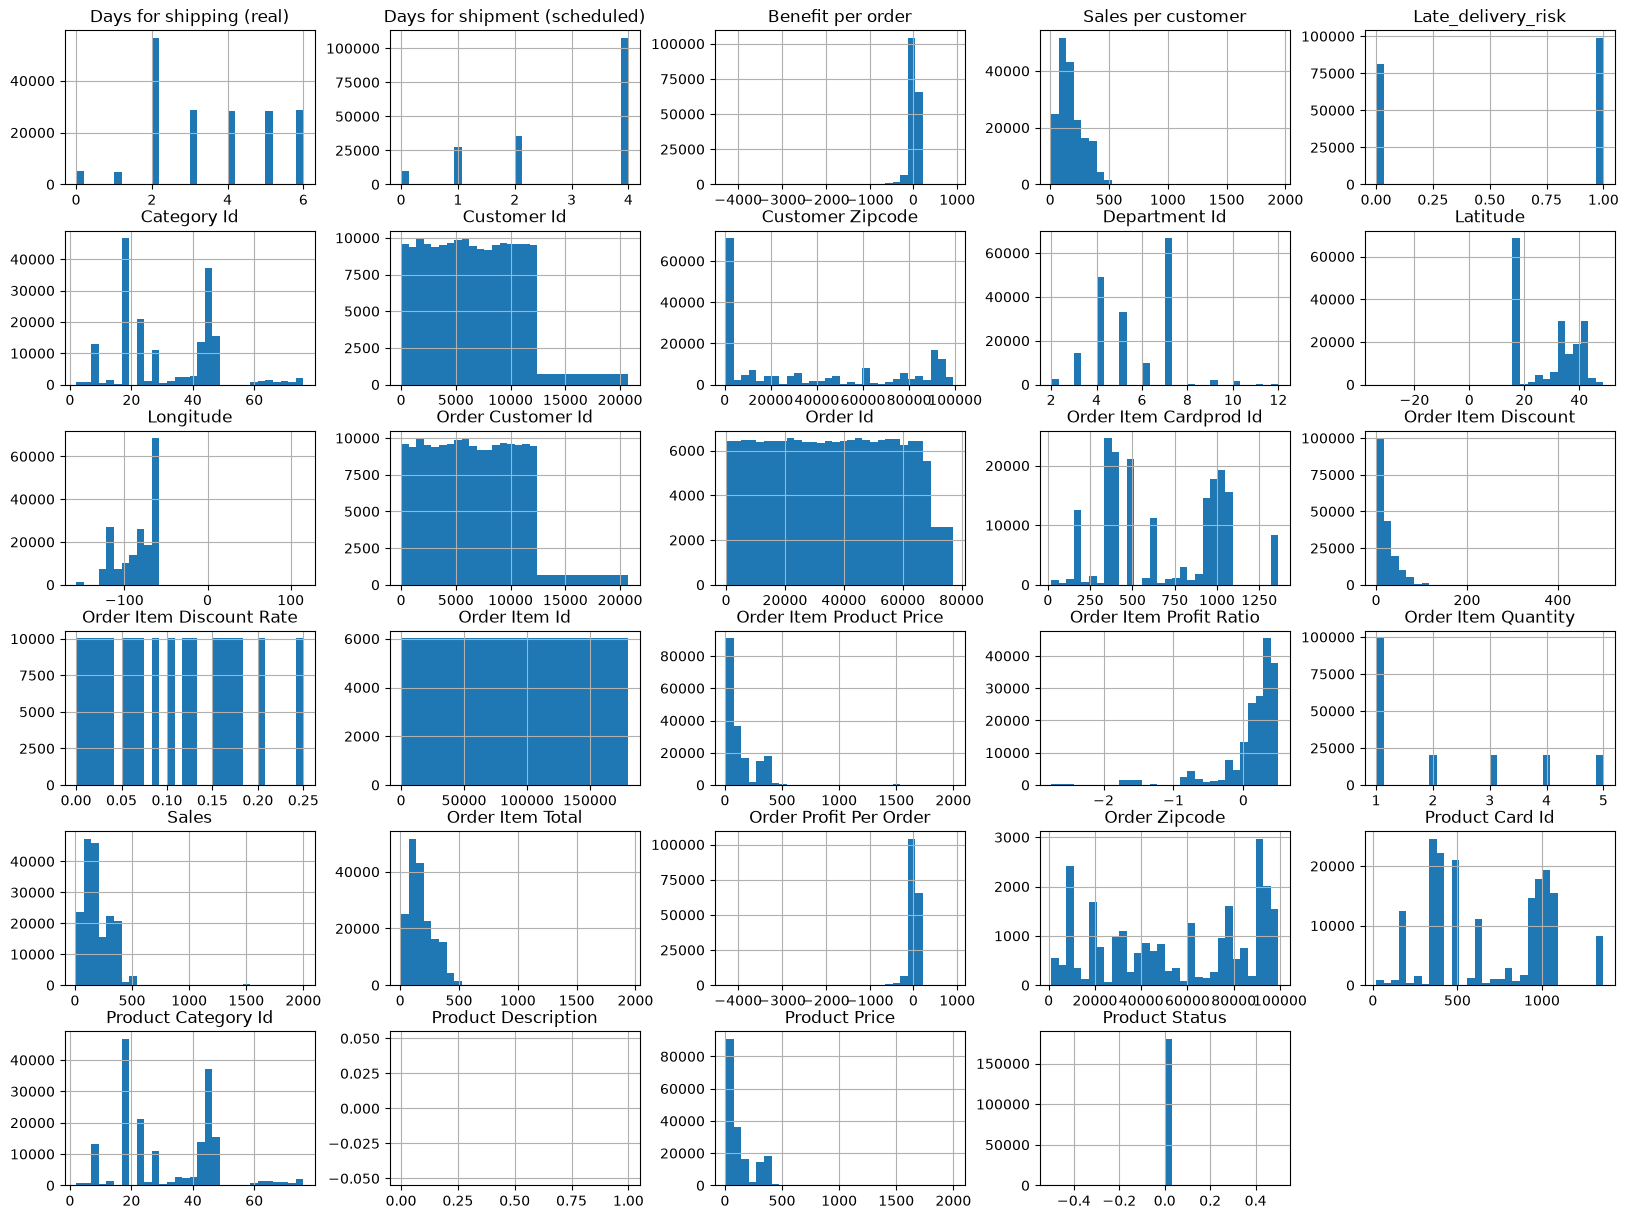

In [29]:
import matplotlib.pyplot as plt
df.hist(bins=30, figsize=(20,15))
plt.show()

<Axes: >

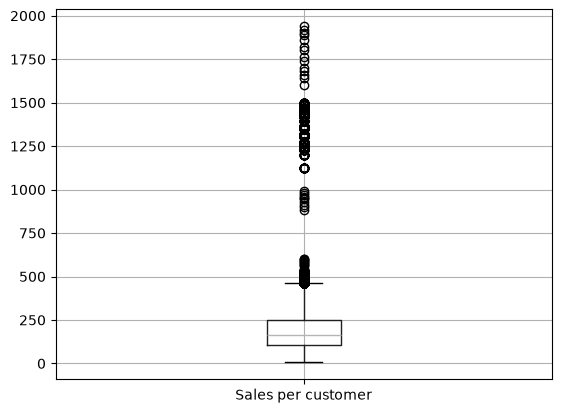

In [33]:
df.boxplot(column=["Sales per customer"])

In [42]:
nb_commandes = df["Order Id"].nunique()
print(len(df),nb_commandes)

verif = df.groupby("Order Id")["Late_delivery_risk"].nunique()
(verif > 1).sum() #compte le nombre de commandes avec des valeurs différentes dans la colonne "Late_delivery_risk"

180508 65741


np.int64(0)

Analyse des valeurs abérrantes (IQR) sur Sales per customer et benefit per order montre -4274.979980	

Matrice de corrélation avec la cible

In [44]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix["Late_delivery_risk"].sort_values(ascending=False) #affiche la corrélation entre les colonnes numériques et la colonne "Late_delivery_risk"

Late_delivery_risk               1.000000
Days for shipping (real)         0.401418
Customer Zipcode                 0.003166
Category Id                      0.001780
Product Category Id              0.001780
Order Item Cardprod Id           0.001513
Product Card Id                  0.001513
Order Customer Id                0.001512
Customer Id                      0.001512
Department Id                    0.001049
Latitude                         0.000700
Order Item Discount Rate         0.000399
Order Item Quantity             -0.000148
Order Item Discount             -0.000739
Order Id                        -0.001273
Order Item Id                   -0.001357
Longitude                       -0.001953
Order Item Product Price        -0.002160
Product Price                   -0.002160
Order Item Profit Ratio         -0.002319
Sales                           -0.003554
Benefit per order               -0.003729
Order Profit Per Order          -0.003729
Order Item Total                -0

In [45]:
#Tri des colonnes en 3 groupes 
print(list(df.columns))

['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Card Id', 'Product Category Id', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrders)', 'Shipping Mode']
